# InOx batch 1 — is Sobol still the best reliable sampler for this design space?

The batch-1 run sheet returned by the fab team (`raw_data_received/inox/06_10_26/`, see
`analysis/inox/inox_sobol_batch1_provenance.ipynb`) is a scrambled Sobol batch of 30 pushed through the campaign's constraint
mapping: the substrate is either room temperature or uniform in a range, and the anneal temperature is drawn above the
substrate temperature. This notebook asks the question the PdO designs and the UIC design (`doe_design_v2.ipynb`) asked of
their generators: **scored as fabricated, on the four space-filling metrics, is Sobol the right choice here, for one batch
and for the batches that will follow?**

* **Generators** (all in the 6-d unit cube, then the same constraint mapping): scrambled **Sobol**, scrambled **Halton**,
  **plain LHS**, **optimised LHS** (scipy random-CD), the **LHS optimised on discrepancy + w × |r|** of the UIC design
  (w = 0.1 in the comparisons, swept in §5) and **uniform random** as the floor; for the sequential check also the
  **optimised LHS + conditional** batch extension of the PdO designs, with and without the correlation penalty.
* **Metrics** (as fabricated, unit cube of the physical bounds): centered L2 discrepancy ↓, min pairwise distance ↑,
  max |factor correlation| ↓ with the substrate–anneal pair excluded (that pair is created by the design rule itself, see the
  provenance notebook §5–7), fill distance ↓ measured against 100 000 *feasible* probe points generated by the same mapping.
* **The space**: the decided one — substrate temperature an integer in 435–600 °C, no room-temperature runs, anneal above
  the substrate up to 600 °C, the other four factors as before. Room-temperature depositions are not part of the campaign
  any more and are not considered here.
* 10 seeds per generator for one batch of 30, 5 seeds for three cumulative batches (30 → 60 → 90); the star in the figures
  is the generator's default seed (42, the seed of the sheet the fab team sent back), re-mapped to this space.

**Decision (2026-10-08).** The fab team has no measurements yet, so batch 1 is **recomputed** rather than edited: integer
substrate temperatures in the range they named, 435–600 °C, and no room-temperature runs (they did not mention any). §5 adds the
discrepancy + w × |r| alternative studied for the UIC design, and **§6 builds the chosen design — the front pick of that
sweep (CD + 0.1 × |r| Latin hypercube, seed 8)** — with its run sheet, pair plot, correlation heatmap and constraint plane,
written to `output/inox/batch1_design/` when their flags are set; the screened Sobol seed and the plain optimised LHS are kept as alternatives.

Nothing is written to disk by default: every figure or table cell starts with its own `SAVE_* = False` flag and `*_FILE`
name — set a flag to True to write that one item (comparison items to `output/inox/batch1_sampler_comparison/`, the design
deliverables of §6 to `output/inox/batch1_design/`).

In [1]:
import os, sys, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import qmc
from scipy.spatial.distance import pdist, cdist
warnings.filterwarnings('ignore')
REPO_ROOT = '/data/zhq7531/IDEAL/DMREF/repository_dmref'
os.chdir(REPO_ROOT)
pd.set_option('display.width', 230); pd.set_option('display.max_columns', 40)
RECEIVED = 'raw_data_received/inox/06_10_26/sobol_constrained_batch_1_repeated (1).xlsx'

# ---- saving: nothing is written by default. Every figure / table cell starts with its own SAVE_* flag (False) and *_FILE name;
#      set a flag to True to write that one item. Comparison items go to OUT_DIR, the design deliverables of §6 to DESIGN_DIR.
OUT_DIR = 'output/inox/batch1_sampler_comparison'      # comparison tables / figures (§2-§5)
DESIGN_DIR = 'output/inox/batch1_design'               # the design to send and its figures (§6)
def save_fig(fig, save, name, folder=None):
    # Write `fig` to folder/name only when `save` is True.
    if not save:
        return
    folder = folder or OUT_DIR; os.makedirs(folder, exist_ok=True); path = os.path.join(folder, name)
    fig.savefig(path, dpi=170, bbox_inches='tight'); print('saved', path)
def save_table(obj, save, name, folder=None):
    # obj = a DataFrame (one sheet) or {sheet name: DataFrame} (multi-sheet workbook); written only when `save` is True.
    if not save:
        return
    folder = folder or OUT_DIR; os.makedirs(folder, exist_ok=True); path = os.path.join(folder, name)
    frames = obj if isinstance(obj, dict) else {'Sheet1': obj}
    with pd.ExcelWriter(path) as w:
        for sheet, d in frames.items():
            d.to_excel(w, sheet_name=sheet, index=not isinstance(d.index, pd.RangeIndex))
    print('saved', path)
P = dict(blue='#2a78d6', orange='#eb6834', green='#1baf7a', muted='#898781', grid='#e1e0d9', axis='#c3c2b7',
         ink='#0b0b0b', ink2='#52514e', surface='#fcfcfb', light='#c9c8c2', purple='#7b61c9', pink='#e0579a')
plt.rcParams.update({'figure.facecolor': P['surface'], 'axes.facecolor': P['surface'], 'axes.edgecolor': P['axis'],
                     'axes.grid': True, 'grid.color': P['grid'], 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'text.color': P['ink'], 'axes.labelcolor': P['ink2'],
                     'xtick.color': P['ink2'], 'ytick.color': P['ink2'], 'xtick.labelsize': 8, 'ytick.labelsize': 8,
                     'axes.labelsize': 9, 'axes.titlesize': 9, 'legend.frameon': False, 'legend.fontsize': 8})
METHOD_COLOURS = {'Sobol (scrambled)': P['blue'], 'Halton (scrambled)': P['green'], 'Plain LHS': P['muted'],
                  'Optimised LHS (random-CD)': P['orange'], 'LHS: discrepancy + 0.1 × |r|': P['pink'], 'Uniform random': P['light'],
                  'Optimised LHS + conditional': P['purple'], 'Weighted LHS + conditional (w = 0.1)': '#b03a73'}
print('saving is per item: each figure / table cell has SAVE_* = False and a *_FILE name; folders', OUT_DIR, 'and', DESIGN_DIR)

saving is per item: each figure / table cell has SAVE_* = False and a *_FILE name; folders output/inox/batch1_sampler_comparison and output/inox/batch1_design


## 1. The design space and the constraint mapping

`map_design` is the generator of `doe/inox/doe_design.ipynb` rewritten to accept **any** unit-cube point set, so every
sampler is pushed through the same rules: power 10–30 W (integer), O₂ flow 0.3–3.0 sccm and pressure 2–4 mTorr (one
decimal), anneal gas 50/50, substrate temperature an integer uniform in 435–600 °C (the room-temperature branch of the
original generator is kept in the code for the check below but switched off, `prob_room_temp = 0`), anneal temperature
uniform between the substrate temperature and 600 °C (integer). The first cell checks that the function with the
original settings reproduces the received sheet value for value, so the comparison runs on the fab team's own mapping.

In [2]:
D = 6
COLS = ['Power (W)', 'Substrate Temperature (C)', 'Oxygen Flow Rate (sccm)', 'Background Pressure (Torr)', 'Annealing Condition', 'Annealing Temperature (C)']

def map_design(U, prob_room_temp=0.14, substrate_bounds=(400.0, 600.0), integer_substrate=False):
    U = np.asarray(U, float); n = len(U)
    power = np.round(10.0 + 20.0 * U[:, 0]).astype(int)
    oxygen = np.round(0.3 + 2.7 * U[:, 2], 1)
    pressure = np.round(2.0 + 2.0 * U[:, 3], 1)
    gas = np.where(U[:, 5] < 0.5, 'N', 'O')
    sub = np.zeros(n); ann = np.zeros(n, dtype=int); eps = 1e-6; lo, hi = substrate_bounds
    for i in range(n):
        if U[i, 1] < prob_room_temp:
            s = 25.0
        else:
            s = lo + ((U[i, 1] - prob_room_temp) / (1.0 - prob_room_temp)) * (hi - lo)
            if integer_substrate:
                s = float(int(np.round(s)))
        lower, upper = max(150.0, s + eps), 600.0
        if lower >= upper:
            s = 598.0; lower = s + eps
        a = int(np.round(lower + U[i, 4] * (upper - lower)))
        if a <= s:
            a = int(np.floor(s)) + 1
        if a > 600:
            a = 600
            if a <= s:
                s = float(a - 1)
        sub[i] = s; ann[i] = a
    return pd.DataFrame({COLS[0]: power, COLS[1]: np.round(sub, 1), COLS[2]: oxygen, COLS[3]: pressure, COLS[4]: gas, COLS[5]: ann})

VARIANTS = {'435-600 °C integer, no RT': dict(prob_room_temp=0.0, substrate_bounds=(435.0, 600.0), integer_substrate=True)}   # the decided space

def unit_bounds(kw):
    # the unit cube of the physical bounds; the substrate axis starts at 25 C when room-temperature runs exist, else at the range's low end
    lo = np.array([10.0, 25.0 if kw['prob_room_temp'] > 0 else kw['substrate_bounds'][0], 0.3, 2.0, 0.0, 150.0])
    hi = np.array([30.0, 600.0, 3.0, 4.0, 1.0, 600.0])
    return lo, hi
def to_unit(df, lo, hi):
    X = df[COLS].copy(); X[COLS[4]] = (X[COLS[4]] == 'O').astype(float)
    return (X.to_numpy(float) - lo) / (hi - lo)
def probes(kw, n=100_000, seed=0):
    # feasible probe points for the fill distance: uniform unit points pushed through the same mapping
    lo, hi = unit_bounds(kw)
    return to_unit(map_design(np.random.default_rng(seed).random((n, D)), **kw), lo, hi)
def metrics(df, kw, Pr):
    lo, hi = unit_bounds(kw); X = to_unit(df, lo, hi)
    C = np.abs(np.corrcoef(X.T)); np.fill_diagonal(C, 0.0)
    sub_ann = C[1, 5]; C[1, 5] = C[5, 1] = 0.0
    return dict(discrepancy=float(qmc.discrepancy(X)), min_dist=float(pdist(X).min()), max_corr=float(C.max()),
                fill_dist=float(cdist(Pr, X).min(axis=1).max()), corr_sub_anneal=float(sub_ann), n_rt=int((df[COLS[1]] == 25).sum()))
KEYS = ['discrepancy', 'min_dist', 'max_corr', 'fill_dist']
PANELS = {'discrepancy': ('Centered L2 discrepancy', 'lower = better'), 'min_dist': ('Min pairwise distance', 'higher = better'),
          'max_corr': ('Max |factor corr.| (substrate–anneal excluded)', 'lower = better'), 'fill_dist': ('Fill distance (largest hole)', 'lower = better')}

def gen_sobol(n, seed):   return qmc.Sobol(d=D, scramble=True, seed=seed).random(n)
def gen_halton(n, seed):  return qmc.Halton(d=D, scramble=True, seed=seed).random(n)
def gen_lhs(n, seed):     return qmc.LatinHypercube(d=D, seed=seed).random(n)
def gen_olhs(n, seed):    return qmc.LatinHypercube(d=D, optimization='random-cd', seed=seed).random(n)
def gen_uniform(n, seed): return np.random.default_rng(seed).random((n, D))
def conditional_olhs(fixed, n_new, seed, n_iter=3000):
    # experiment04's batch-extension optimiser: column swaps inside the new LHS, kept only if the discrepancy of [fixed; new] drops
    rng = np.random.default_rng(seed); Pn = gen_olhs(n_new, seed)
    score = lambda: qmc.discrepancy(np.vstack([fixed, Pn]) if len(fixed) else Pn)
    best = score()
    for _ in range(n_iter):
        col = rng.integers(D); a, b = rng.choice(n_new, 2, replace=False)
        Pn[[a, b], col] = Pn[[b, a], col]
        cand = score()
        if cand < best: best = cand
        else: Pn[[a, b], col] = Pn[[b, a], col]
    return Pn

def map_unit(U, kw, lo, hi):
    # vectorised twin of map_design -> unit-cube coordinates directly (no DataFrame); used inside the optimisation loop
    U = np.asarray(U, float); p, (slo, shi), integer = kw['prob_room_temp'], kw['substrate_bounds'], kw['integer_substrate']
    power = np.round(10.0 + 20.0 * U[:, 0]); oxygen = np.round(0.3 + 2.7 * U[:, 2], 1); pressure = np.round(2.0 + 2.0 * U[:, 3], 1)
    gas = (U[:, 5] >= 0.5).astype(float)
    s = np.where(U[:, 1] < p, 25.0, slo + ((U[:, 1] - p) / (1.0 - p if p < 1 else 1.0)) * (shi - slo))
    if integer:
        s = np.where(U[:, 1] < p, 25.0, np.round(s))
    lower = np.maximum(150.0, s + 1e-6)
    bad = lower >= 600.0; s = np.where(bad, 598.0, s); lower = np.where(bad, s + 1e-6, lower)
    a = np.round(lower + U[:, 4] * (600.0 - lower))
    a = np.where(a <= s, np.floor(s) + 1, a)
    over = a > 600; a = np.where(over, 600.0, a); s = np.where(over & (a <= s), a - 1, s)
    X = np.column_stack([power, np.round(s, 1), oxygen, pressure, gas, a])
    return (X - lo) / (hi - lo)

def weighted_lhs(n, seed, kw, w, n_iter=2500):
    rng = np.random.default_rng(seed); U = gen_olhs(n, seed); lo, hi = unit_bounds(kw)
    def objective(U):
        X = map_unit(U, kw, lo, hi); C = np.abs(np.corrcoef(X.T)); np.fill_diagonal(C, 0.0); C[1, 5] = C[5, 1] = 0.0
        return float(qmc.discrepancy(U)) + w * float(C.max())      # uniformity in the generator's cube, correlation as fabricated
    best = objective(U)
    for _ in range(n_iter):
        col = rng.integers(D); a, b = rng.choice(n, 2, replace=False)
        U[[a, b], col] = U[[b, a], col]
        cand = objective(U)
        if cand < best: best = cand
        else: U[[a, b], col] = U[[b, a], col]
    return U

def conditional_weighted_lhs(fixed, n_new, seed, kw, w=0.1, n_iter=3000):
    # the batch-extension optimiser with the same penalty: unit-cube discrepancy of [fixed; new] + w x max |r| of the fabricated cumulative design
    rng = np.random.default_rng(seed); Pn = gen_olhs(n_new, seed); lo, hi = unit_bounds(kw)
    def objective():
        U = np.vstack([fixed, Pn]) if len(fixed) else Pn
        X = map_unit(U, kw, lo, hi); C = np.abs(np.corrcoef(X.T)); np.fill_diagonal(C, 0.0); C[1, 5] = C[5, 1] = 0.0
        return float(qmc.discrepancy(U)) + w * float(C.max())
    best = objective()
    for _ in range(n_iter):
        col = rng.integers(D); a, b = rng.choice(n_new, 2, replace=False)
        Pn[[a, b], col] = Pn[[b, a], col]
        cand = objective()
        if cand < best: best = cand
        else: Pn[[a, b], col] = Pn[[b, a], col]
    return Pn

W_DEFAULT = 0.1                                            # the correlation weight carried into the comparisons (§5 sweeps it)
KW0 = next(iter(VARIANTS.values()))
METHODS = {'Sobol (scrambled)': gen_sobol, 'Halton (scrambled)': gen_halton, 'Plain LHS': gen_lhs,
           'Optimised LHS (random-CD)': gen_olhs, f'LHS: discrepancy + {W_DEFAULT:g} × |r|': lambda n, seed: weighted_lhs(n, seed, KW0, W_DEFAULT),
           'Uniform random': gen_uniform}

PROBES = {v: probes(kw) for v, kw in VARIANTS.items()}
Ut = np.random.default_rng(1).random((500, D)); lo0, hi0 = unit_bounds(KW0)
assert np.allclose(map_unit(Ut, KW0, lo0, hi0), to_unit(map_design(Ut, **KW0), lo0, hi0)), 'vectorised mapping differs from map_design'
rec = pd.read_excel(RECEIVED).drop_duplicates('Sample').reset_index(drop=True)
print('Sobol seed 42 through the original mapping (400-600 C, 14 % RT) == received sheet:',
      map_design(gen_sobol(30, 42), prob_room_temp=0.14, substrate_bounds=(400.0, 600.0))[COLS].equals(rec[COLS]))
ON_TABLE = {v: map_design(gen_sobol(30, 42), **kw) for v, kw in VARIANTS.items()}       # the generator's default seed in the decided space
pd.DataFrame(VARIANTS).T

Sobol seed 42 through the original mapping (400-600 C, 14 % RT) == received sheet: True


,prob_room_temp,substrate_bounds,integer_substrate
"435-600 °C integer, no RT",0.0,"(435.0, 600.0)",True


## 2. One batch of 30: six generators, ten seeds

60 designs scored in 11 s


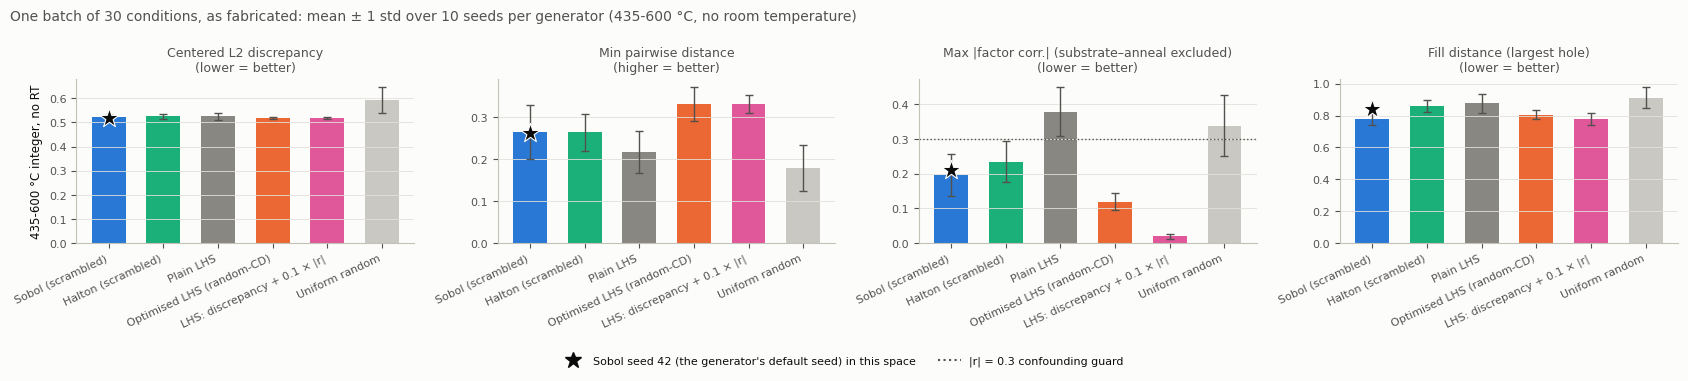

discrepancy        min_dist        max_corr        fill_dist        corr_sub_anneal       
                                                              mean    std     mean    std     mean    std      mean    std            mean    std
variant                   method                                                                                                                 
435-600 °C integer, no RT Sobol (scrambled)                  0.521  0.010    0.265  0.065    0.195  0.061     0.780  0.039           0.669  0.076
                          Halton (scrambled)                 0.526  0.011    0.265  0.044    0.234  0.060     0.857  0.038           0.677  0.047
                          Plain LHS                          0.526  0.014    0.217  0.050    0.378  0.071     0.876  0.060           0.679  0.088
                          Optimised LHS (random-CD)          0.518  0.004    0.331  0.041    0.119  0.024     0.805  0.028           0.654  0.012
                          LHS: discrepancy + 0.1 × |r|       0.518  0.004    0.332  0.022    0.020  0.007     0.780  0.039           0.658  0.033
                          Uniform random                     0.593  0.053    0.179  0.055    0.338  0.088     0.912  0.065           0.668  0.124

                                                       discrepancy        min_dist        max_corr        fill_dist        corr_sub_anneal       
                                                              mean    std     mean    std     mean    std      mean    std            mean    std
variant                   method                                                                                                                 
435-600 °C integer, no RT Sobol (scrambled)                  0.521  0.010    0.265  0.065    0.195  0.061     0.780  0.039           0.669  0.076
                          Halton (scrambled)                 0.526  0.011    0.265  0.044    0.234  0.060     0.857  0.038           0.677  0.047
                          Plain LHS                          0.526  0.014    0.217  0.050    0.378  0.071     0.876  0.060           0.679  0.088
                          Optimised LHS (random-CD)          0.518  0.004    0.331  0.041    0.119  0.024     0.805  0.028  

,discrepancy,min_dist,max_corr,fill_dist,corr_sub_anneal,n_rt
Sobol seed 42 in this space,0.518,0.262,0.209,0.843,0.658,0.0


In [3]:
# ---- saving (set a flag to True to write that item)
SAVE_SINGLE_BATCH_FIG = False;  SINGLE_BATCH_FIG_FILE = 'sampler_comparison_single_batch.png'
SAVE_SINGLE_BATCH_TABLE = False;  SINGLE_BATCH_TABLE_FILE = 'sampler_comparison_single_batch.xlsx'

N, N_SEEDS = 30, 10
t0 = time.time(); rows = []
for v, kw in VARIANTS.items():
    for m, g in METHODS.items():
        for s in range(N_SEEDS):
            rows.append(dict(variant=v, method=m, seed=s, **metrics(map_design(g(N, s), **kw), kw, PROBES[v])))
single = pd.DataFrame(rows)
on_table = {v: metrics(ON_TABLE[v], kw, PROBES[v]) for v, kw in VARIANTS.items()}
print(f'{len(single)} designs scored in {time.time() - t0:.0f} s')

names = list(METHODS)
fig, axes = plt.subplots(len(VARIANTS), 4, figsize=(17, 3.6 * len(VARIANTS)), sharex=True); axes = np.atleast_2d(axes)
for r, v in enumerate(VARIANTS):
    sub = single[single.variant == v]
    for c, k in enumerate(KEYS):
        ax = axes[r, c]; g = sub.groupby('method', sort=False)[k]
        ax.bar(range(len(names)), g.mean().reindex(names), yerr=g.std().reindex(names), width=0.62, capsize=3,
               color=[METHOD_COLOURS[m] for m in names], error_kw=dict(ecolor=P['ink2'], lw=1))
        ax.scatter([0], [on_table[v][k]], marker='*', s=210, color=P['ink'], edgecolor='white', lw=0.8, zorder=5)
        if k == 'max_corr':
            ax.axhline(0.3, ls=':', color=P['ink2'], lw=1)
        if r == 0:
            ax.set_title(f'{PANELS[k][0]}\n({PANELS[k][1]})', fontsize=9, color=P['ink2'])
        if c == 0:
            ax.set_ylabel(v, fontsize=8.5, color=P['ink'])
        ax.grid(axis='x', visible=False)
for ax in axes[-1]:
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=25, ha='right', fontsize=8)
handles = [Line2D([], [], marker='*', ls='', color=P['ink'], markersize=12, label="Sobol seed 42 (the generator's default seed) in this space"),
           Line2D([], [], ls=':', color=P['ink2'], label='|r| = 0.3 confounding guard')]
fig.legend(handles=handles, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f'One batch of {N} conditions, as fabricated: mean ± 1 std over {N_SEEDS} seeds per generator (435-600 °C, no room temperature)',
             x=0.01, ha='left', fontsize=10, color=P['ink2'])
fig.tight_layout(rect=(0, 0.05, 1, 1)); save_fig(fig, SAVE_SINGLE_BATCH_FIG, SINGLE_BATCH_FIG_FILE); plt.show()

summary = single.groupby(['variant', 'method'], sort=False)[KEYS + ['corr_sub_anneal']].agg(['mean', 'std']).round(3)
table_on = pd.DataFrame({'Sobol seed 42 in this space': on_table[v] for v in VARIANTS}).T.round(3)
save_table({'per_seed': single, 'summary': summary, 'on_the_table': table_on.rename_axis('design').reset_index()}, SAVE_SINGLE_BATCH_TABLE, SINGLE_BATCH_TABLE_FILE)
display(summary); print(summary.to_string()); display(table_on)

**Reading §2.** Discrepancy does not separate the generators (0.518–0.526 for all but uniform random at 0.593). The other
three metrics do:

* **The LHS optimised on discrepancy + 0.1 × |r| is best or tied-best on every metric**: closest pair 0.33 (tied with the
  optimised LHS), factor correlation 0.02 (an order of magnitude below everything else), largest hole 0.78 (tied with
  Sobol). The penalty costs nothing against the plain optimised LHS it starts from.
* **Among the un-penalised generators the decision splits.** The optimised LHS has the cleaner factors and the wider
  spacing (correlation 0.12 vs 0.20, closest pair 0.33 vs 0.27); Sobol has the smaller holes (0.78 vs 0.81) and is second
  on the other two; Halton trails Sobol on correlation and coverage.
* **Plain LHS fails the guard on average** (0.38) and uniform random is worst everywhere: a batch of 30 in six dimensions
  needs either an optimised Latin structure or a balanced sequence to keep the factors independent.
* **The generator's default seed 42** (the star) is an unlucky draw in this space: correlation 0.21 is fine, but its largest
  hole (0.84) is worse than the Sobol average, which is why §4 screens seeds.

For a single batch, then, the weighted LHS is the best generator; what separates it from Sobol is what happens when
batches are added (§3).

## 3. Three cumulative batches (30 → 60 → 90): sequences versus batch generators

Sobol and Halton continue their sequence (what the generator's `batch_number` fast-forward does); plain and optimised LHS
draw a fresh batch each round and the batches are pooled; **optimised LHS + conditional** designs each new batch in the
gaps of everything fabricated so far (the PdO campaign's batch-extension optimiser), and **weighted LHS + conditional**
does the same with the correlation penalty of §5 on the cumulative fabricated design. Metrics of the cumulative design
after each round, mean ± 1 std over 5 seeds.

90 cumulative designs scored in 27 s


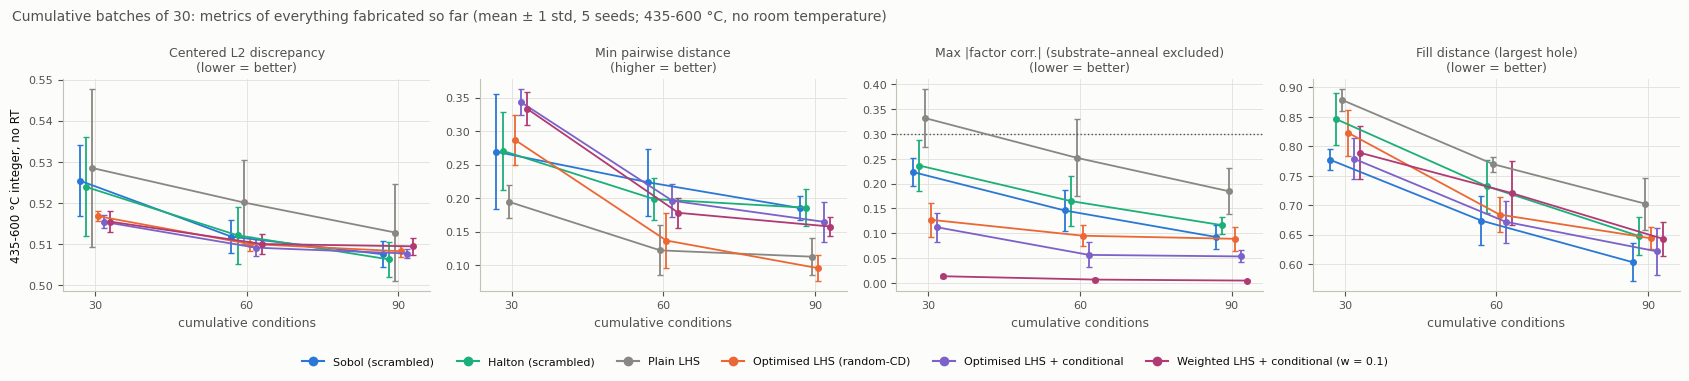

discrepancy  min_dist  max_corr  fill_dist
variant                   method                               n_cum                                            
435-600 °C integer, no RT Sobol (scrambled)                    30           0.525     0.269     0.223      0.778
                          Halton (scrambled)                   30           0.524     0.271     0.237      0.847
                          Plain LHS                            30           0.529     0.195     0.332      0.879
                          Optimised LHS (random-CD)            30           0.517     0.287     0.127      0.823
                          Optimised LHS + conditional          30           0.515     0.343     0.112      0.779
                          Weighted LHS + conditional (w = 0.1) 30           0.515     0.334     0.013      0.789
                          Sobol (scrambled)                    60           0.512     0.224     0.146      0.674
                          Halton (scrambled)                   60           0.512     0.199     0.165      0.732
                          Plain LHS                            60           0.520     0.122     0.252      0.770
                          Optimised LHS (random-CD)            60           0.510     0.137     0.095      0.684
                          Optimised LHS + conditional          60           0.509     0.196     0.056      0.672
                          Weighted LHS + conditional (w = 0.1) 60           0.510     0.178     0.007      0.721
                          Sobol (scrambled)                    90           0.508     0.185     0.092      0.603
                          Halton (scrambled)                   90           0.506     0.186     0.116      0.648
                          Plain LHS                            90           0.513     0.113     0.185      0.703
                          Optimised LHS (random-CD)            90           0.508     0.096     0.089      0.644
                          Optimised LHS + conditional          90           0.508     0.165     0.053      0.622
                          Weighted LHS + conditional (w = 0.1) 90           0.509     0.158     0.005      0.643

                                                                      discrepancy  min_dist  max_corr  fill_dist
variant                   method                               n_cum                                            
435-600 °C integer, no RT Sobol (scrambled)                    30           0.525     0.269     0.223      0.778
                          Halton (scrambled)                   30           0.524     0.271     0.237      0.847
                          Plain LHS                            30           0.529     0.195     0.332      0.879
                          Optimised LHS (random-CD)            30           0.517     0.287     0.127      0.823
                          Optimised LHS + conditional          30           0.515     0.343     0.112      0.779
                          Weighted LHS + conditional (w = 0.1) 30           0.515     0.334     0.013      0.789
                          Sobol (scrambled)                    60           0.512     0.224     

In [4]:
# ---- saving (set a flag to True to write that item)
SAVE_SEQUENTIAL_FIG = False;  SEQUENTIAL_FIG_FILE = 'sampler_comparison_sequential.png'
SAVE_SEQUENTIAL_TABLE = False;  SEQUENTIAL_TABLE_FILE = 'sampler_comparison_sequential.xlsx'

ROUNDS, SEEDS_SEQ = 3, 5
SEQ_METHODS = ['Sobol (scrambled)', 'Halton (scrambled)', 'Plain LHS', 'Optimised LHS (random-CD)', 'Optimised LHS + conditional', 'Weighted LHS + conditional (w = 0.1)']
t0 = time.time(); rows = []
for v, kw in VARIANTS.items():
    for s in range(SEEDS_SEQ):
        pools = {m: np.empty((0, D)) for m in SEQ_METHODS}
        eng_s = qmc.Sobol(d=D, scramble=True, seed=s); eng_h = qmc.Halton(d=D, scramble=True, seed=s)
        for r in range(ROUNDS):
            sr = s * 100 + r
            new = {'Sobol (scrambled)': eng_s.random(N), 'Halton (scrambled)': eng_h.random(N), 'Plain LHS': gen_lhs(N, sr),
                   'Optimised LHS (random-CD)': gen_olhs(N, sr), 'Optimised LHS + conditional': conditional_olhs(pools['Optimised LHS + conditional'], N, sr),
                   'Weighted LHS + conditional (w = 0.1)': conditional_weighted_lhs(pools['Weighted LHS + conditional (w = 0.1)'], N, sr, kw, W_DEFAULT)}
            for m in SEQ_METHODS:
                pools[m] = np.vstack([pools[m], new[m]])
                rows.append(dict(variant=v, method=m, seed=s, round=r + 1, n_cum=(r + 1) * N, **metrics(map_design(pools[m], **kw), kw, PROBES[v])))
seq = pd.DataFrame(rows)
print(f'{len(seq)} cumulative designs scored in {time.time() - t0:.0f} s')

fig, axes = plt.subplots(len(VARIANTS), 4, figsize=(17, 3.6 * len(VARIANTS)), sharex=True); axes = np.atleast_2d(axes)
for r, v in enumerate(VARIANTS):
    sub = seq[seq.variant == v]
    for c, k in enumerate(KEYS):
        ax = axes[r, c]
        for m in SEQ_METHODS:
            g = sub[sub.method == m].groupby('n_cum')[k]
            ax.errorbar(g.mean().index + (SEQ_METHODS.index(m) - 2.5) * 1.2, g.mean(), yerr=g.std(), fmt='o-', ms=4, lw=1.3, capsize=2,
                        color=METHOD_COLOURS[m], label=m)
        if k == 'max_corr':
            ax.axhline(0.3, ls=':', color=P['ink2'], lw=1)
        if r == 0:
            ax.set_title(f'{PANELS[k][0]}\n({PANELS[k][1]})', fontsize=9, color=P['ink2'])
        if c == 0:
            ax.set_ylabel(v, fontsize=8.5, color=P['ink'])
        ax.set_xticks([N, 2 * N, 3 * N])
for ax in axes[-1]:
    ax.set_xlabel('cumulative conditions')
fig.legend(handles=[Line2D([], [], marker='o', color=METHOD_COLOURS[m], label=m) for m in SEQ_METHODS], loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f'Cumulative batches of {N}: metrics of everything fabricated so far (mean ± 1 std, {SEEDS_SEQ} seeds; 435-600 °C, no room temperature)', x=0.01, ha='left', fontsize=10, color=P['ink2'])
fig.tight_layout(rect=(0, 0.05, 1, 1)); save_fig(fig, SAVE_SEQUENTIAL_FIG, SEQUENTIAL_FIG_FILE); plt.show()
seq_summary = seq.groupby(['variant', 'method', 'n_cum'], sort=False)[KEYS].mean().round(3)
save_table({'per_seed': seq, 'summary': seq_summary}, SAVE_SEQUENTIAL_TABLE, SEQUENTIAL_TABLE_FILE); display(seq_summary); print(seq_summary.to_string())

**Reading §3.** Once batches accumulate the Sobol sequence pulls ahead on geometry. Pooling fresh Latin hypercubes is the
worst way to grow a design: the closest pair of the pooled optimised LHS collapses (0.29 → 0.14 → 0.10) because each new
batch is blind to the previous ones, and its holes close more slowly. Sobol keeps the widest spacing from 60 conditions on
(0.22 at 60, 0.19 at 90, level with Halton) and the smallest holes at every size (0.67 at 60, 0.60 at 90). The two
conditional optimisers are the batch generators that compete: the un-penalised one matches Sobol on holes at 60 (0.67) and
keeps correlation at 0.05–0.06; the **weighted conditional LHS keeps the factor correlation at ≈ 0.01 at every size**
(0.013 → 0.007 → 0.005) with spacing between the two (0.16 at 90) but slightly larger holes than Sobol as the design
grows (0.72 vs 0.67 at 60, 0.64 vs 0.60 at 90) — the penalty buys factor independence at a small, growing cost in
coverage. Both conditional variants need the custom optimisation per batch. Discrepancy stays a tie for every method
except plain LHS.

## 4. Is the generator's default seed a reliable one? Sobol seed screening, and n = 30 versus 32

Scrambled Sobol keeps its balance properties only for n = 2ᵏ; batch 1 has 30 conditions. Two checks: (a) the four metrics for
50 Sobol seeds, with the generator's default seed 42 marked, to see whether that draw is typical, lucky or unlucky in this
space; (b) the same metrics at n = 32 for comparison.

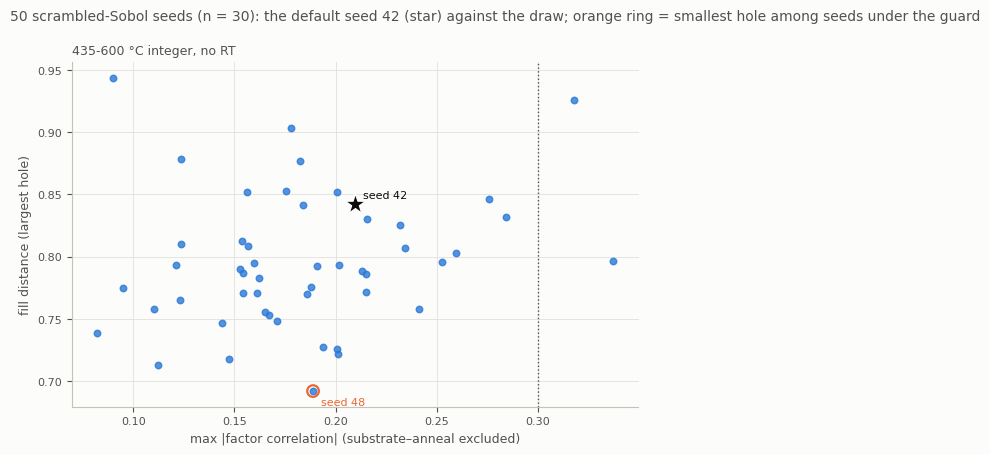

,seed42_max_corr,seed42_rank_corr,seed42_fill,seed42_rank_fill,seed42_min_dist,seed42_rank_min_dist,seeds_under_guard,best_seed_under_guard,best_max_corr,best_fill
variant,,,,,,,,,,
"435-600 °C integer, no RT",0.209,37/50,0.843,41/50,0.262,39/50,48,48,0.189,0.692


variant               435-600 °C integer, no RT
seed42_max_corr                           0.209
seed42_rank_corr                          37/50
seed42_fill                               0.843
seed42_rank_fill                          41/50
seed42_min_dist                           0.262
seed42_rank_min_dist                      39/50
seeds_under_guard                            48
best_seed_under_guard                        48
best_max_corr                             0.189
best_fill                                 0.692
Sobol at n = 30 vs 32 (mean of 10 seeds):


,discrepancy,min_dist,max_corr,fill_dist
n,,,,
30,0.521,0.265,0.195,0.780
32,0.518,0.265,0.145,0.751


    discrepancy  min_dist  max_corr  fill_dist
n                                             
30        0.521     0.265     0.195      0.780
32        0.518     0.265     0.145      0.751


In [5]:
# ---- saving (set a flag to True to write that item)
SAVE_SEED_SCREEN_FIG = False;  SEED_SCREEN_FIG_FILE = 'sobol_seed_screening.png'
SAVE_SEED_SCREEN_TABLE = False;  SEED_SCREEN_TABLE_FILE = 'sobol_seed_screening.xlsx'

SEEDS_SCREEN = range(50)
rows = []
for v, kw in VARIANTS.items():
    for s in SEEDS_SCREEN:
        rows.append(dict(variant=v, seed=s, **metrics(map_design(gen_sobol(N, s), **kw), kw, PROBES[v])))
screen = pd.DataFrame(rows)
ranks = []
for v in VARIANTS:
    sub = screen[screen.variant == v].copy()
    sub['rank_max_corr'] = sub['max_corr'].rank().astype(int); sub['rank_fill'] = sub['fill_dist'].rank().astype(int); sub['rank_min_dist'] = sub['min_dist'].rank(ascending=False).astype(int)
    s42 = sub[sub.seed == 42].iloc[0]
    best = sub[sub.max_corr < 0.3].sort_values('fill_dist').iloc[0]
    ranks.append(dict(variant=v, seed42_max_corr=round(s42.max_corr, 3), seed42_rank_corr=f"{int(s42.rank_max_corr)}/50", seed42_fill=round(s42.fill_dist, 3),
                      seed42_rank_fill=f"{int(s42.rank_fill)}/50", seed42_min_dist=round(s42.min_dist, 3), seed42_rank_min_dist=f"{int(s42.rank_min_dist)}/50",
                      seeds_under_guard=int((sub.max_corr < 0.3).sum()), best_seed_under_guard=int(best.seed), best_max_corr=round(best.max_corr, 3), best_fill=round(best.fill_dist, 3)))
rank_tbl = pd.DataFrame(ranks).set_index('variant')

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(6.5 * len(VARIANTS), 4.6), sharey=True); axes = np.atleast_1d(axes)
for ax, v in zip(axes, VARIANTS):
    sub = screen[screen.variant == v]
    ax.scatter(sub.max_corr, sub.fill_dist, s=22, color=P['blue'], alpha=0.8, zorder=3)
    s42 = sub[sub.seed == 42].iloc[0]
    ax.scatter([s42.max_corr], [s42.fill_dist], marker='*', s=230, color=P['ink'], edgecolor='white', lw=0.8, zorder=5)
    ax.annotate('seed 42', (s42.max_corr, s42.fill_dist), xytext=(6, 4), textcoords='offset points', fontsize=8, color=P['ink'])
    b = rank_tbl.loc[v]
    bb = sub[sub.seed == b.best_seed_under_guard].iloc[0]
    ax.scatter([bb.max_corr], [bb.fill_dist], marker='o', s=70, facecolor='none', edgecolor=P['orange'], lw=1.6, zorder=5)
    ax.annotate(f'seed {int(b.best_seed_under_guard)}', (bb.max_corr, bb.fill_dist), xytext=(6, -10), textcoords='offset points', fontsize=8, color=P['orange'])
    ax.axvline(0.3, ls=':', color=P['ink2'], lw=1)
    ax.set_xlabel('max |factor correlation| (substrate–anneal excluded)'); ax.set_title(v, loc='left', fontsize=9, color=P['ink2'])
axes[0].set_ylabel('fill distance (largest hole)')
fig.suptitle(f'50 scrambled-Sobol seeds (n = {N}): the default seed 42 (star) against the draw; orange ring = smallest hole among seeds under the guard',
             x=0.01, ha='left', fontsize=10, color=P['ink2'])
fig.tight_layout(); save_fig(fig, SAVE_SEED_SCREEN_FIG, SEED_SCREEN_FIG_FILE); plt.show()

n32 = pd.DataFrame([dict(n=n, **pd.DataFrame([metrics(map_design(gen_sobol(n, s), **VARIANTS[list(VARIANTS)[0]]), VARIANTS[list(VARIANTS)[0]], PROBES[list(VARIANTS)[0]]) for s in range(N_SEEDS)])[KEYS].mean().round(3).to_dict())
                    for n in (30, 32)]).set_index('n')
save_table({'seeds': screen, 'seed42_vs_best': rank_tbl.reset_index(), 'n30_vs_n32': n32.reset_index()}, SAVE_SEED_SCREEN_TABLE, SEED_SCREEN_TABLE_FILE)
display(rank_tbl); print(rank_tbl.T.to_string()); print('Sobol at n = 30 vs 32 (mean of 10 seeds):'); display(n32); print(n32.to_string())

**Reading §4.** 48 of the 50 seeds stay under the correlation guard, so the generator is reliable in that sense, but the
draws differ a lot in coverage (largest hole 0.69–0.92). The default seed 42 is below average on all three metrics in
this space (ranks 37, 41 and 39 of 50 for correlation, hole size and closest pair); the best seed under the guard, 48, has
a largest hole of 0.69 against 0.84. The power-of-two question is minor here: at n = 32 the mean correlation (0.15 vs 0.20)
and hole size (0.75 vs 0.78) improve a little, so two extra conditions would help Sobol slightly if the chamber allows
them, but screening the seed buys more.

## 5. The alternative studied for the UIC design: an LHS optimised on discrepancy + w × max |r|

In `doe_design_v2.ipynb` (UIC) the design was optimised on centered L2 discrepancy with an optional correlation penalty,
score = discrepancy + w × max |r|, swept over w and read on a Pareto front. The same study here, adapted to the constrained
space: start from scipy's optimised LHS in the unit cube, swap two values inside one column (the Latin structure is kept)
and keep the swap only if **discrepancy of the design in the unit cube + w × max |factor correlation| of the fabricated
design (substrate–anneal excluded)** goes down. The discrepancy is taken in the generator's cube on purpose: that is the
space in which "uniform" means uniform over the feasible region. Taking it on the fabricated points instead rewards
collinear temperatures — a check with that objective drove the substrate–anneal correlation from its natural 0.65 to 0.97,
because the centered L2 discrepancy measured against the full cube is lowest when the points crowd the feasible
triangle's diagonal. The correlation term is evaluated after the mapping, so it is the quantity the guard checks. Weights
w = 0, 0.02, 0.05, 0.1, 0.2, 0.5 (unit-cube discrepancy ≈ 0.5, |r| ≈ 0.1–0.3), 10 seeds each, in the decided variant
(435–600 °C, integers, no room temperature). The Sobol pick of §6 and the §4 screening are the references.

60 weighted designs in 43 s


discrepancy        min_dist        max_corr        fill_dist        corr_sub_anneal       
                   mean    std     mean    std     mean    std      mean    std            mean    std
corr_weight                                                                                           
0.00              0.517  0.003    0.329  0.026    0.120  0.035     0.799  0.043           0.659  0.022
0.02              0.517  0.003    0.322  0.032    0.037  0.010     0.796  0.037           0.662  0.024
0.05              0.518  0.004    0.291  0.045    0.025  0.010     0.799  0.058           0.665  0.030
0.10              0.518  0.004    0.332  0.022    0.020  0.007     0.780  0.039           0.658  0.033
0.20              0.519  0.003    0.312  0.046    0.016  0.005     0.788  0.050           0.653  0.030
0.50              0.520  0.007    0.311  0.048    0.015  0.004     0.778  0.036           0.643  0.052

            discrepancy        min_dist        max_corr        fill_dist        corr_sub_anneal       
                   mean    std     mean    std     mean    std      mean    std            mean    std
corr_weight                                                                                           
0.00              0.517  0.003    0.329  0.026    0.120  0.035     0.799  0.043           0.659  0.022
0.02              0.517  0.003    0.322  0.032    0.037  0.010     0.796  0.037           0.662  0.024
0.05              0.518  0.004    0.291  0.045    0.025  0.010     0.799  0.058           0.665  0.030
0.10              0.518  0.004    0.332  0.022    0.020  0.007     0.780  0.039           0.658  0.033
0.20              0.519  0.003    0.312  0.046    0.016  0.005     0.788  0.050           0.653  0.030
0.50              0.520  0.007    0.311  0.048    0.015  0.004     0.778  0.036           0.643  0.052


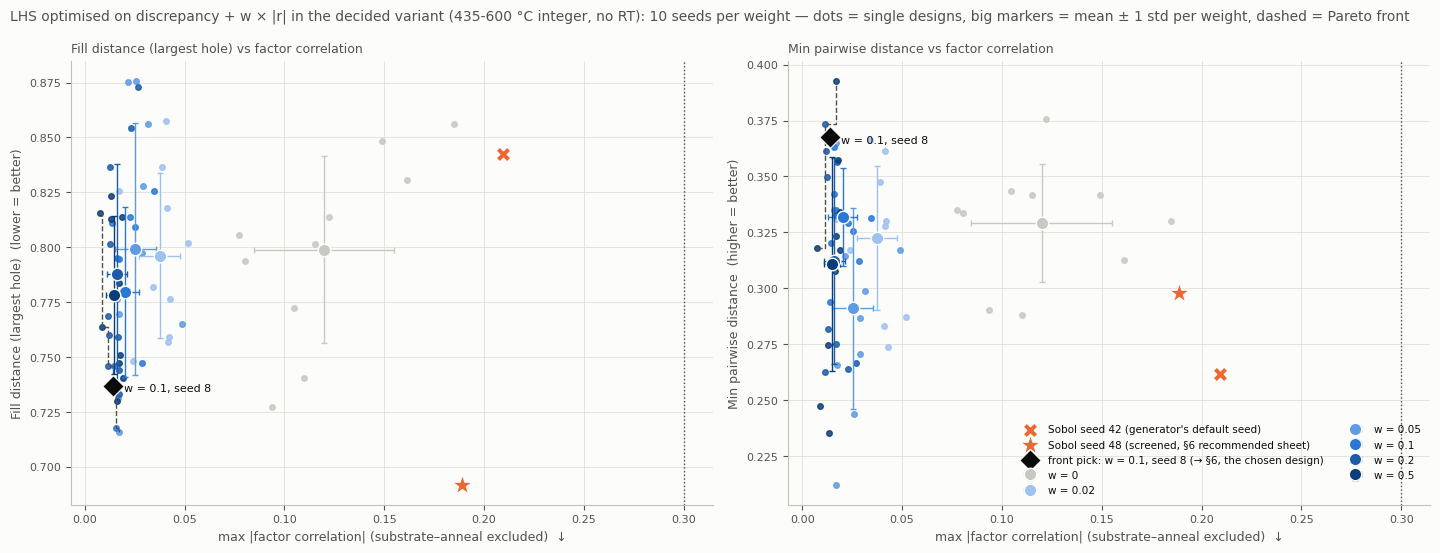

designs on the 3-objective front (|r| ↓, fill ↓, min dist ↑), plus the Sobol references:


,corr_weight,seed,pick,discrepancy,min_dist,max_corr,fill_dist,corr_sub_anneal
0,0.5,8,False,0.524,0.318,0.008,0.816,0.637
1,0.5,7,False,0.525,0.247,0.009,0.764,0.642
2,0.2,8,False,0.517,0.373,0.012,0.769,0.707
3,0.2,1,False,0.521,0.262,0.012,0.746,0.619
4,0.2,9,False,0.517,0.361,0.012,0.760,0.629
5,0.1,8,True,0.520,0.368,0.014,0.737,0.696
6,0.1,2,False,0.525,0.342,0.016,0.717,0.628
7,0.5,9,False,0.512,0.393,0.017,0.784,0.690
8,0.05,1,False,0.519,0.266,0.017,0.716,0.629
9,0.2,6,False,0.516,0.356,0.017,0.733,0.635


   corr_weight  seed   pick  discrepancy  min_dist  max_corr  fill_dist  corr_sub_anneal
0          0.5     8  False        0.524     0.318     0.008      0.816            0.637
1          0.5     7  False        0.525     0.247     0.009      0.764            0.642
2          0.2     8  False        0.517     0.373     0.012      0.769            0.707
3          0.2     1  False        0.521     0.262     0.012      0.746            0.619
4          0.2     9  False        0.517     0.361     0.012      0.760            0.629
5          0.1     8   True        0.520     0.368     0.014      0.737            0.696
6          0.1     2  False        0.525     0.342     0.016      0.717            0.628
7          0.5     9  False        0.512     0.393     0.017      0.784            0.690
8         0.05     1  False        0.519     0.266     0.017      0.716            0.629
9          0.2     6  False        0.516     0.356     0.017      0.733            0.635
10       Sobol    42 

In [6]:
# ---- saving (set a flag to True to write that item)
SAVE_SWEEP_FIG = False;  SWEEP_FIG_FILE = 'corr_weight_sweep_pareto.png'
SAVE_SWEEP_TABLE = False;  SWEEP_TABLE_FILE = 'corr_weight_sweep.xlsx'

V = '435-600 °C integer, no RT'; kw = VARIANTS[V]; Pr = PROBES[V]; lo_, hi_ = unit_bounds(kw)
WEIGHTS, SEEDS_W = [0.0, 0.02, 0.05, 0.1, 0.2, 0.5], range(10)
t0 = time.time(); rows, U_sweep = [], {}
for w in WEIGHTS:
    for s_ in SEEDS_W:
        U_sweep[(w, s_)] = weighted_lhs(N, s_, kw, w)
        rows.append(dict(corr_weight=w, seed=s_, **metrics(map_design(U_sweep[(w, s_)], **kw), kw, Pr)))
sweep = pd.DataFrame(rows)
print(f'{len(sweep)} weighted designs in {time.time() - t0:.0f} s')
sw_summary = sweep.groupby('corr_weight')[KEYS + ['corr_sub_anneal']].agg(['mean', 'std']).round(3); display(sw_summary); print(sw_summary.to_string())

def pareto_mask(df, minimize, maximize):
    vals = np.column_stack([df[c].to_numpy() for c in minimize] + [-df[c].to_numpy() for c in maximize])
    keep = np.ones(len(df), bool)
    for i in range(len(df)):
        dominated = np.all(vals <= vals[i], axis=1) & np.any(vals < vals[i], axis=1); dominated[i] = False
        keep[i] = not dominated.any()
    return keep
sob_ref = {s_: metrics(map_design(gen_sobol(N, s_), **kw), kw, Pr) for s_ in (42, int(screen[(screen.variant == V) & (screen.max_corr < 0.3)].sort_values('fill_dist').iloc[0].seed))}
sweep['on_front'] = pareto_mask(sweep, minimize=['max_corr', 'fill_dist'], maximize=['min_dist'])
# the front pick: among front designs with |r| <= 0.15 (half the guard) and the structural pair at its natural level, the best
# rank-sum of largest hole (small) and closest pair (large) - the design carried into §6 as the weighted alternative
cand_w = sweep[sweep.on_front & (sweep.max_corr <= 0.15) & (sweep.corr_sub_anneal <= 0.75)].copy()
cand_w['rank_sum'] = cand_w.fill_dist.rank() + cand_w.min_dist.rank(ascending=False)
cand_w = cand_w.sort_values(['rank_sum', 'fill_dist'])
W_PICK = (float(cand_w.iloc[0].corr_weight), int(cand_w.iloc[0].seed)); pick_m = cand_w.iloc[0]
sweep['pick'] = (sweep.corr_weight == W_PICK[0]) & (sweep.seed == W_PICK[1])

W_COL = dict(zip(WEIGHTS, [P['light'], '#9ec2ef', '#5f9be3', P['blue'], '#1d5cab', '#0b3d7a']))
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
for ax, ykey, better in zip(axes, ['fill_dist', 'min_dist'], ['lower', 'higher']):
    for w in WEIGHTS:
        sub = sweep[sweep.corr_weight == w]
        ax.scatter(sub.max_corr, sub[ykey], s=16, color=W_COL[w], alpha=0.85, zorder=3)
        ax.errorbar(sub.max_corr.mean(), sub[ykey].mean(), xerr=sub.max_corr.std(), yerr=sub[ykey].std(), fmt='o', ms=9, color=W_COL[w],
                    markeredgecolor='white', capsize=2, lw=1, zorder=5, label=f'w = {w:g}')
    fr = sweep[pareto_mask(sweep, minimize=['max_corr'] + (['fill_dist'] if ykey == 'fill_dist' else []), maximize=['min_dist'] if ykey == 'min_dist' else [])].sort_values('max_corr')
    ax.step(fr.max_corr, fr[ykey], where='post', ls='--', lw=1, color=P['ink2'], zorder=4)
    for s_, mk, lab in [(42, 'X', "Sobol seed 42 (generator's default seed)"), (list(sob_ref)[1], '*', f'Sobol seed {list(sob_ref)[1]} (screened, §6 recommended sheet)')]:
        ax.scatter([sob_ref[s_]['max_corr']], [sob_ref[s_][ykey]], marker=mk, s=230 if mk == '*' else 110, color=P['orange'], edgecolor='white', lw=0.8, zorder=6, label=lab)
    ax.scatter([pick_m.max_corr], [pick_m[ykey]], marker='D', s=120, color=P['ink'], edgecolor='white', lw=0.8, zorder=7,
               label=f'front pick: w = {W_PICK[0]:g}, seed {W_PICK[1]} (→ §6, the chosen design)')
    ax.annotate(f'w = {W_PICK[0]:g}, seed {W_PICK[1]}', (pick_m.max_corr, pick_m[ykey]), xytext=(8, -4), textcoords='offset points', fontsize=8, color=P['ink'])
    ax.axvline(0.3, ls=':', color=P['ink2'], lw=1)
    ax.set_xlabel('max |factor correlation| (substrate–anneal excluded)  ↓'); ax.set_ylabel(f'{PANELS[ykey][0]}  ({better} = better)')
    ax.set_title(f'{PANELS[ykey][0]} vs factor correlation', loc='left', fontsize=9, color=P['ink2'])
axes[1].legend(loc='lower right', fontsize=7.5, ncol=2)
fig.suptitle(f'LHS optimised on discrepancy + w × |r| in the decided variant ({V}): {len(SEEDS_W)} seeds per weight — '
             'dots = single designs, big markers = mean ± 1 std per weight, dashed = Pareto front', x=0.01, ha='left', fontsize=10, color=P['ink2'])
fig.tight_layout(); save_fig(fig, SAVE_SWEEP_FIG, SWEEP_FIG_FILE); plt.show()

front = sweep[sweep.on_front].sort_values('max_corr')[['corr_weight', 'seed', 'pick'] + KEYS + ['corr_sub_anneal']].round(3)
refs = pd.DataFrame([dict(corr_weight='Sobol', seed=s_, pick=False, **{k: round(v, 3) for k, v in m.items() if k in KEYS + ['corr_sub_anneal']}) for s_, m in sob_ref.items()])
print('designs on the 3-objective front (|r| ↓, fill ↓, min dist ↑), plus the Sobol references:')
front_tbl = pd.concat([front, refs], ignore_index=True); display(front_tbl); print(front_tbl.to_string())
save_table({'per_design': sweep, 'summary': sw_summary, 'front': front}, SAVE_SWEEP_TABLE, SWEEP_TABLE_FILE)

**Reading §5.** The penalty works immediately and costs nothing measurable. Discrepancy only (w = 0, which is scipy's
optimised LHS re-optimised by column swaps) leaves a mean factor correlation of 0.12; w = 0.02 cuts it to 0.04 and
w ≥ 0.1 to ≈ 0.02, while discrepancy (0.517 → 0.520), the largest hole (0.80 → 0.78) and the closest pair (0.29–0.33)
stay inside the seed-to-seed spread, and the substrate–anneal pair keeps its natural ≈ 0.65 because the objective never
touches it. As in the UIC sweep, no w = 0 design is on the front: every discrepancy-only design is beaten by a penalised
one. Against the Sobol references the front designs win factor correlation by an order of magnitude (≤ 0.017 against 0.19
and 0.21) and most win the closest pair (0.32–0.39 against 0.30); on the largest hole the screened Sobol seed 48 (0.69, the
best of 50 draws) still edges the front's best (0.72–0.74). The balanced front pick (black diamond, w = 0.1, seed 8) is the design chosen for batch 1 (§6); the §2 bars show the
same generator at w = 0.1 over ten seeds, so the pick can be read against the method averages as well.

Is the alternative worth it? On paper yes: it is the best single batch in this study, with the cleanest factor separation.
In practice the gain is small for the model — at |r| = 0.19 the variance inflation of a linear effect is 1/(1 − r²) ≈ 1.04,
at 0.014 it is 1.00 — and the design must be re-optimised conditional on batch 1 when batch 2 comes (the conditional
optimiser of §3, which can carry the same penalty), where the Sobol sequence simply continues.

## 6. The chosen design: the CD + 0.1 × |r| Latin hypercube, seed 8 (the §5 front pick)

Decision 2026-10-08: batch 1 is the weighted front pick of §5. This section is the deliverable — the run sheet in the fab
team's layout (`Sample`, `Repetition`, the six factors; the pressure column keeps its "(Torr)" header for compatibility,
the values are mTorr), the unique conditions, the pair plot, the correlation heatmap and the constraint plane — plus the
two alternatives (screened Sobol seed, plain optimised LHS) for the record. Each item has its own flag at the top of
the cell; **the run sheet to send is `DESIGN_WORKBOOK_FILE`, written by `SAVE_DESIGN_WORKBOOK = True`** into
`output/inox/batch1_design/`.

,discrepancy,min_dist,max_corr,fill_dist,corr_sub_anneal,n_rt
"CHOSEN: LHS on CD + 0.1 × |r|, seed 8 (§5 front pick)",0.520,0.368,0.014,0.737,0.696,0.0
"alternative: Sobol, screened seed 48 (batch 2 = fast-forward of the sequence)",0.523,0.298,0.189,0.692,0.680,0.0
"alternative: optimised LHS, screened seed 49",0.521,0.368,0.081,0.731,0.652,0.0
"reference: Sobol seed 42 (the generator's default seed, in this space)",0.518,0.262,0.209,0.843,0.658,0.0


                                                                               discrepancy  min_dist  max_corr  fill_dist  corr_sub_anneal  n_rt
CHOSEN: LHS on CD + 0.1 × |r|, seed 8 (§5 front pick)                                0.520     0.368     0.014      0.737            0.696   0.0
alternative: Sobol, screened seed 48 (batch 2 = fast-forward of the sequence)        0.523     0.298     0.189      0.692            0.680   0.0
alternative: optimised LHS, screened seed 49                                         0.521     0.368     0.081      0.731            0.652   0.0
reference: Sobol seed 42 (the generator's default seed, in this space)               0.518     0.262     0.209      0.843            0.658   0.0

chosen design: 90 rows = 30 conditions x 3 repetitions; substrate 436-599 C (integers), anneal 481-600 C, anneal > substrate for all: True, gas O/N: {'N': 15, 'O': 15}, power 10-30 W, O2 0.4-3 sccm, pressure 2-4 mTorr


,Sample,Power (W),Substrate Temperature (C),Oxygen Flow Rate (sccm),Background Pressure (Torr),Annealing Condition,Annealing Temperature (C)
0,1,22,533.0,3.0,2.5,N,544
1,2,15,525.0,2.4,2.9,N,594
2,3,13,579.0,0.6,2.6,O,596
3,4,27,594.0,2.0,2.6,N,598
4,5,25,544.0,1.1,3.6,N,577
5,6,19,538.0,0.6,4.0,O,577
6,7,30,569.0,1.3,2.2,O,577
7,8,14,496.0,2.8,3.6,O,586
8,9,28,487.0,1.8,3.8,N,575
9,10,11,558.0,1.6,3.8,N,571


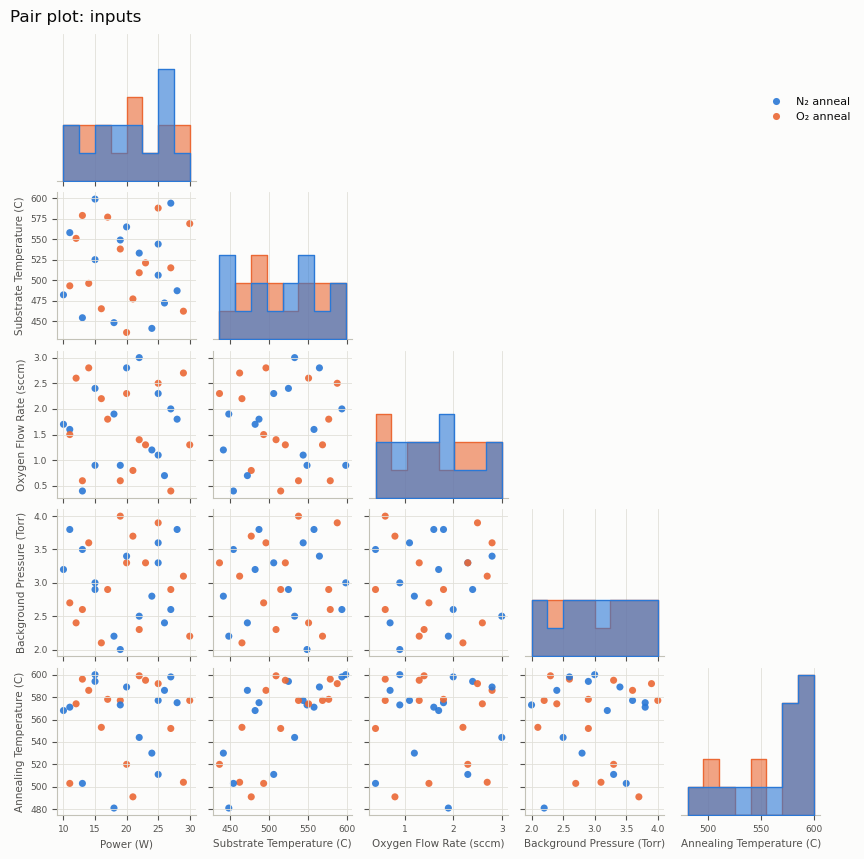

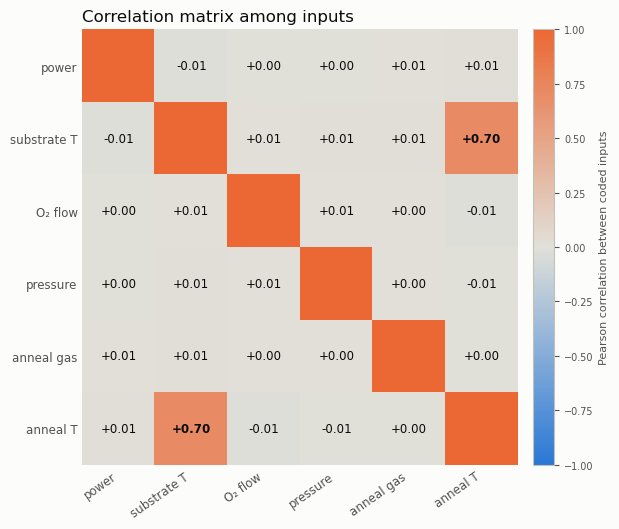

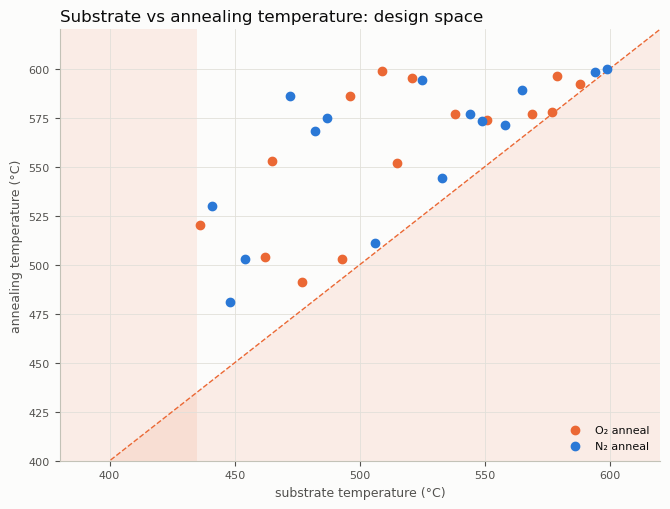

In [7]:
# ---- saving (set a flag to True to write that item)
SAVE_DESIGN_WORKBOOK = False;  DESIGN_WORKBOOK_FILE = 'inox_batch1_design_435_600_noRT_cd_wcorr_lhs.xlsx'
SAVE_DESIGN_PAIRPLOT = False;  DESIGN_PAIRPLOT_FILE = 'inox_batch1_design_pairplot.png'
SAVE_DESIGN_CORRELATION = False;  DESIGN_CORRELATION_FILE = 'inox_batch1_design_correlation.png'
SAVE_DESIGN_CONSTRAINT = False;  DESIGN_CONSTRAINT_FILE = 'inox_batch1_design_constraint_plane.png'
SAVE_ALT_SOBOL_SHEET = False;  ALT_SOBOL_SHEET_FILE = 'alternative_sobol_seed_screened_repeated.xlsx'
SAVE_ALT_OLHS_SHEET = False;  ALT_OLHS_SHEET_FILE = 'alternative_optimised_lhs_repeated.xlsx'

V = '435-600 °C integer, no RT'; kw = VARIANTS[V]; Pr = PROBES[V]
chosen = map_design(U_sweep[W_PICK], **kw)                                         # the §5 front pick
unique = chosen.assign(Sample=np.arange(1, N + 1))[['Sample'] + COLS]
def repeated(df, n_rep=3):
    out = df.loc[df.index.repeat(n_rep)].reset_index(drop=True)
    out.insert(1, 'Repetition', out.groupby('Sample').cumcount() + 1)
    return out
sheet = repeated(unique)
m_chosen = metrics(chosen, kw, Pr)
# the alternatives, for the record
sob = screen[screen.variant == V]; olhs = pd.DataFrame([dict(seed=s_, **metrics(map_design(gen_olhs(N, s_), **kw), kw, Pr)) for s_ in SEEDS_SCREEN])
def pick(df):
    ok = df[df.max_corr < 0.3]; return int(ok.sort_values('fill_dist').iloc[0].seed)
SOBOL_SEED, OLHS_SEED = pick(sob), pick(olhs)
alt_sobol = map_design(gen_sobol(N, SOBOL_SEED), **kw); alt_olhs = map_design(gen_olhs(N, OLHS_SEED), **kw)
choice = pd.DataFrame({f'CHOSEN: LHS on CD + {W_PICK[0]:g} × |r|, seed {W_PICK[1]} (§5 front pick)': m_chosen,
                       f'alternative: Sobol, screened seed {SOBOL_SEED} (batch 2 = fast-forward of the sequence)': metrics(alt_sobol, kw, Pr),
                       f'alternative: optimised LHS, screened seed {OLHS_SEED}': metrics(alt_olhs, kw, Pr),
                       "reference: Sobol seed 42 (the generator's default seed, in this space)": on_table[V]}).T.round(3)
display(choice); print(choice.to_string())
print(f'\nchosen design: {len(sheet)} rows = {N} conditions x 3 repetitions; substrate {chosen[COLS[1]].min():g}-{chosen[COLS[1]].max():g} C (integers), '
      f'anneal {chosen[COLS[5]].min()}-{chosen[COLS[5]].max()} C, anneal > substrate for all: {bool((chosen[COLS[1]] < chosen[COLS[5]]).all())}, '
      f'gas O/N: {chosen[COLS[4]].value_counts().to_dict()}, power {chosen[COLS[0]].min()}-{chosen[COLS[0]].max()} W, '
      f'O2 {chosen[COLS[2]].min():g}-{chosen[COLS[2]].max():g} sccm, pressure {chosen[COLS[3]].min():g}-{chosen[COLS[3]].max():g} mTorr')
display(unique)

# ---- pair plot of the five numeric factors, anneal gas in colour
import seaborn as sns
d = unique.copy(); d['gas'] = d[COLS[4]].map({'O': 'O₂ anneal', 'N': 'N₂ anneal'})
NUMC = [COLS[0], COLS[1], COLS[2], COLS[3], COLS[5]]
g = sns.pairplot(d[NUMC + ['gas']], hue='gas', palette={'O₂ anneal': P['orange'], 'N₂ anneal': P['blue']}, corner=True,
                 diag_kind='hist', height=1.7, plot_kws=dict(s=26, alpha=0.9, edgecolor='none'), diag_kws=dict(alpha=0.6, bins=8, element='step'))
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=6.5); ax.xaxis.label.set_size(7.5); ax.yaxis.label.set_size(7.5)
g.figure.suptitle('Pair plot: inputs', x=0.02, ha='left', y=1.01, fontsize=12, color=P['ink'])
sns.move_legend(g, 'upper right', bbox_to_anchor=(0.92, 0.92), title=None, frameon=False)
save_fig(g.figure, SAVE_DESIGN_PAIRPLOT, DESIGN_PAIRPLOT_FILE, DESIGN_DIR); plt.show()

# ---- correlation heatmap of the coded inputs
from matplotlib.colors import LinearSegmentedColormap
cmap_div = LinearSegmentedColormap.from_list('div', [P['blue'], P['grid'], P['orange']])
lo_, hi_ = unit_bounds(kw); X = to_unit(chosen, lo_, hi_); r = np.corrcoef(X.T)
labels = ['power', 'substrate T', 'O₂ flow', 'pressure', 'anneal gas', 'anneal T']
fig, ax = plt.subplots(figsize=(6.2, 5.4))
im = ax.imshow(r, cmap=cmap_div, vmin=-1, vmax=1)
for i in range(6):
    for j in range(6):
        if i != j:
            ax.text(j, i, f'{(0.0 if abs(r[i, j]) < 0.005 else r[i, j]):+.2f}', ha='center', va='center', fontsize=8.5, color=P['ink'], fontweight='bold' if abs(r[i, j]) >= 0.3 else 'normal')
ax.set_xticks(range(6)); ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=8.5); ax.set_yticks(range(6)); ax.set_yticklabels(labels, fontsize=8.5)
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03); cb.set_label('Pearson correlation between coded inputs', fontsize=8); cb.ax.tick_params(labelsize=7)
off = np.abs(r.copy()); np.fill_diagonal(off, 0); sa = off[1, 5]; off[1, 5] = off[5, 1] = 0
ax.set_title('Correlation matrix among inputs', loc='left', fontsize=12, color=P['ink'])
fig.tight_layout(); save_fig(fig, SAVE_DESIGN_CORRELATION, DESIGN_CORRELATION_FILE, DESIGN_DIR); plt.show()

# ---- constraint plane
fig, ax = plt.subplots(figsize=(6.8, 5.2))
ax.fill_between([0, 650], [0, 650], 0, color=P['orange'], alpha=0.10, lw=0); ax.plot([0, 650], [0, 650], color=P['orange'], lw=1, ls='--')
ax.axvspan(0, 435, color=P['orange'], alpha=0.10, lw=0)
for gas, c in [('O', P['orange']), ('N', P['blue'])]:
    sel = unique[unique[COLS[4]] == gas]
    ax.scatter(sel[COLS[1]], sel[COLS[5]], s=36, color=c, zorder=4, label=f'{gas}₂ anneal')
ax.set_xlim(380, 620); ax.set_ylim(400, 620); ax.set_xlabel('substrate temperature (°C)'); ax.set_ylabel('annealing temperature (°C)')
ax.set_title('Substrate vs annealing temperature: design space', loc='left', fontsize=12, color=P['ink'])
ax.legend(loc='lower right'); fig.tight_layout(); save_fig(fig, SAVE_DESIGN_CONSTRAINT, DESIGN_CONSTRAINT_FILE, DESIGN_DIR); plt.show()

# ---- the workbook: fab layout + unique + config + provenance + alternatives
config = pd.DataFrame([
    dict(factor=COLS[0], range='10 - 30', step='1 W', note='as in the original generator'),
    dict(factor=COLS[1], range='435 - 600', step='1 °C (integer)', note='fab team request 2026-10; no room-temperature runs'),
    dict(factor=COLS[2], range='0.3 - 3.0', step='0.1 sccm', note='as in the original generator'),
    dict(factor=COLS[3], range='2.0 - 4.0', step='0.1 mTorr', note='values are mTorr; header "(Torr)" kept as in the fab team sheet'),
    dict(factor=COLS[4], range='O / N', step='2 levels, 50/50', note='O = O2 anneal, N = N2 anneal'),
    dict(factor=COLS[5], range='substrate T + 1 - 600', step='1 °C (integer)', note='drawn uniformly above the substrate temperature (design rule)')])
prov = pd.DataFrame([
    dict(property='campaign', value='InOx TFT - batch 1 (recomputed 2026-10-08 from the fab team request: integer substrate 435-600 C, no RT)'),
    dict(property='generator', value=f'Latin hypercube in the 6-d unit cube (scipy LatinHypercube random-CD, seed {W_PICK[1]}) re-optimised by column swaps on centered L2 discrepancy + {W_PICK[0]:g} x max|r| of the fabricated design (substrate-anneal pair excluded), 2500 swaps; then the constraint mapping of doe/inox/doe_design.ipynb'),
    dict(property='chosen how', value='front pick of the w sweep (w = 0, 0.02, 0.05, 0.1, 0.2, 0.5 x 10 seeds): on the 3-objective Pareto front, |r| <= 0.15, best rank-sum of largest hole and closest pair'),
    dict(property='metrics (unit cube of the bounds, as fabricated)', value=', '.join(f'{k} = {v:.3f}' for k, v in m_chosen.items() if k != 'n_rt')),
    dict(property='alternatives in this workbook', value=f'Sobol seed {SOBOL_SEED} (screened) and optimised LHS seed {OLHS_SEED}; see sheet "alternatives"'),
    dict(property='repetitions', value='3 per condition (Repetition 1-3), 90 rows'),
    dict(property='notebook', value='doe/inox/inox_batch1_sampler_comparison.ipynb (section 6); comparison of generators in sections 2-5'),
    dict(property='written', value=pd.Timestamp.today().strftime('%Y-%m-%d'))])
save_table({'design_full': sheet, 'design_unique': unique, 'config': config, 'provenance': prov,
                         'alternatives': choice.rename_axis('design').reset_index()}, SAVE_DESIGN_WORKBOOK, DESIGN_WORKBOOK_FILE, DESIGN_DIR)
save_table(repeated(alt_sobol.assign(Sample=np.arange(1, N + 1))[['Sample'] + COLS]), SAVE_ALT_SOBOL_SHEET, ALT_SOBOL_SHEET_FILE, DESIGN_DIR)
save_table(repeated(alt_olhs.assign(Sample=np.arange(1, N + 1))[['Sample'] + COLS]), SAVE_ALT_OLHS_SHEET, ALT_OLHS_SHEET_FILE, DESIGN_DIR)

**Reading §6.** Thirty integer substrate temperatures spread over 435–600 °C with an anneal above each, 15 O₂ and 15 N₂
anneals, power, O₂ flow and pressure covering their full ranges without duplicates (the pair plot), and no factor pair above
|r| = 0.02 except the substrate–anneal pair that the design rule imposes (the heatmap). Against the Sobol alternative the
chosen design has the wider spacing and the cleaner factors; against the plain optimised LHS it has the same spacing and
a factor correlation six times lower. The workbook carries the fab-layout sheet to send, the unique conditions, the factor
configuration, the provenance (generator, seed, weight, metrics) and the alternatives for the record.

## 7. Verdict — is Sobol still the best reliable option?

1. **For one batch of 30, no: the LHS optimised on discrepancy + w × |r| is best or tied on all four metrics** (closest pair
   0.33, correlation 0.02, largest hole 0.78). Among the un-penalised generators Sobol and the optimised LHS split the
   decision (Sobol smaller holes, optimised LHS cleaner factors and wider spacing); discrepancy is a tie for all of them.
2. **For a campaign that keeps adding batches, Sobol is the geometric winner, the weighted conditional LHS the
   statistical one.** Pooling fresh Latin hypercubes degrades badly. The Sobol sequence keeps the widest spacing and the
   smallest holes as it grows, with no optimisation step — the "reliable" part. The weighted conditional LHS keeps the
   factor correlation at ≈ 0.01 at every size, at a small and growing cost in coverage (0.64 vs 0.60 at 90) and with the
   custom batch optimiser each round.
3. **The weak point of Sobol is the seed, not the method.** The default seed 42 is a below-average draw in this space
   (largest hole 0.84 against 0.69 for the screened seed 48); the Sobol alternative kept in §6 uses the screened seed.
4. **Plain LHS and uniform random are out**: both fail the correlation guard on average at this size.
5. **The front pick of the weighted sweep (w = 0.1, seed 8; black diamond in §5)** is the best single design in the study:
   closest pair 0.37, correlation 0.014, largest hole 0.74. The practical difference from the screened Sobol seed is small
   for a GP (variance inflation 1.04 vs 1.00); what it gives up is the free batch-to-batch extension.

**Decision (2026-10-08): batch 1 is the weighted front pick** (§6) — factor independence and single-batch quality were
preferred over the free sequence extension. When batch 2 is designed, use the weighted conditional optimiser of §3 on top
of the fabricated batch 1 (it keeps |r| ≈ 0.01 as the design grows); the screened Sobol seed stays in the workbook as the
alternative.